# Person 4 visualization: degradation, recovery, and parameter sensitivity

This notebook analyzes `treatment_grid.csv` from the four-parameter sweep over κ_b, d_a, φ_max, and ξ. It creates parameter-space heatmaps and time-course sensitivity plots.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from dataclasses import replace

from ma2024_model import DEFAULT_PARAMS
from sweep_engine import simulate_logspace

CSV_PATH = Path('treatment_grid.csv')
df = pd.read_csv(CSV_PATH)
print(df.shape)
display(df.head())

PARAMS = ['kappa_b', 'd_a', 'phi_max', 'xi']
LABELS = {'kappa_b': 'κ_b', 'd_a': 'd_a', 'phi_max': 'φ_max', 'xi': 'ξ'}
OUTCOMES = {
    'diversity_final': 'Final Shannon diversity',
    't_recovery_S': 'Sensitive-cell recovery time',
    'peak_loss_total': 'Peak total-population loss',
    'f_R_final': 'Final resistant fraction',
    'ns_final': 'Final sensitive-cell density',
    'nr_final': 'Final resistant-cell density',
}
for p in PARAMS: print(p, sorted(df[p].unique())[:3], '...', sorted(df[p].unique())[-3:])

(194481, 16)


,kappa_b,d_a,phi_max,xi,f_R_final,resistant_eliminated,sensitive_survives,t_recovery_S,t_steady_state,ss_converged,peak_loss_S,peak_loss_total,diversity_final,diversity_min,ns_final,nr_final
0,0.0,0.0,0.0,0.00,0.224561,True,False,0.0,150.0,False,1.0,1.0,0.532621,0.532621,2.738129e-13,7.929425e-14
1,0.0,0.0,0.0,0.05,0.222397,True,False,0.0,150.0,False,1.0,1.0,0.529924,0.529924,2.079833e-13,5.948374e-14
2,0.0,0.0,0.0,0.10,0.220354,True,False,0.0,150.0,False,1.0,1.0,0.527356,0.527356,1.601825e-13,4.527304e-14
3,0.0,0.0,0.0,0.15,0.218425,True,False,0.0,150.0,False,1.0,1.0,0.524907,0.524907,1.249598e-13,3.492225e-14
4,0.0,0.0,0.0,0.20,0.216600,True,False,0.0,150.0,False,1.0,1.0,0.522570,0.522570,9.864908e-14,2.727514e-14


kappa_b [0.0, 0.05, 0.1] ... [0.9, 0.95, 1.0]
d_a [0.0, 0.005, 0.01] ... [0.09, 0.095, 0.1]
phi_max [0.0, 0.25, 0.5] ... [4.5, 4.75, 5.0]
xi [0.0, 0.05, 0.1] ... [0.9, 0.95, 1.0]


## 1. Heatmap helper

Because four parameters cannot all be placed on one ordinary 2-D heatmap, each heatmap varies two parameters on the axes and holds the other two at selected slice values. The default slice is the value closest to the model baseline.

In [2]:
BASELINE = {'kappa_b': DEFAULT_PARAMS.kappa_b, 'd_a': DEFAULT_PARAMS.d_a, 'phi_max': DEFAULT_PARAMS.phi_max, 'xi': DEFAULT_PARAMS.xi}

def nearest_value(parameter, value=None):
    target = BASELINE[parameter] if value is None else value
    values = df[parameter].unique()
    return values[np.argmin(np.abs(values - target))]

def heatmap(outcome, x, y, fixed=None, cmap='viridis', center=None):
    fixed = fixed or {}
    subset = df.copy()
    used = {}
    for p in PARAMS:
        if p not in (x, y):
            v = nearest_value(p, fixed.get(p))
            subset = subset[np.isclose(subset[p], v)]
            used[p] = v
    table = subset.pivot(index=y, columns=x, values=outcome).sort_index()
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(table, ax=ax, cmap=cmap, center=center, cbar_kws={'label': OUTCOMES.get(outcome, outcome)})
    ax.set_xlabel(LABELS[x])
    ax.set_ylabel(LABELS[y])
    ax.set_title(f'{OUTCOMES.get(outcome, outcome)}: {LABELS[x]} vs {LABELS[y]}\n' + ', '.join(f'{LABELS[k]}={v:g}' for k,v in used.items()))
    plt.tight_layout()
    return fig, ax

## 2. Main phase-diagram heatmaps

This pair is especially interpretable: κ_b and ξ jointly describe biological clearance and nutrient recycling, while d_a and φ_max are held near baseline.

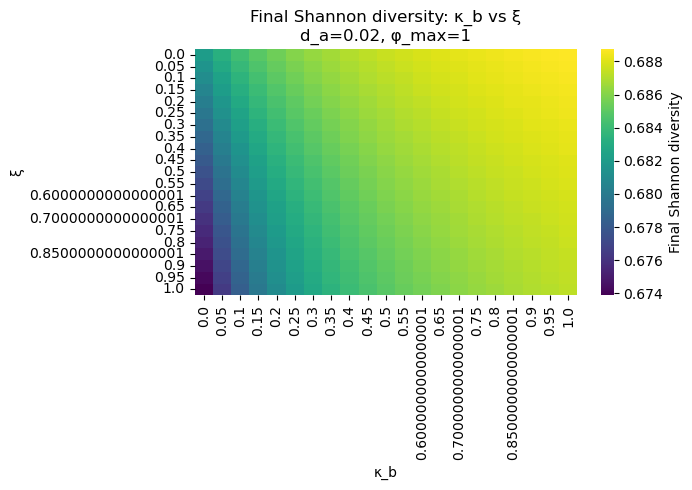

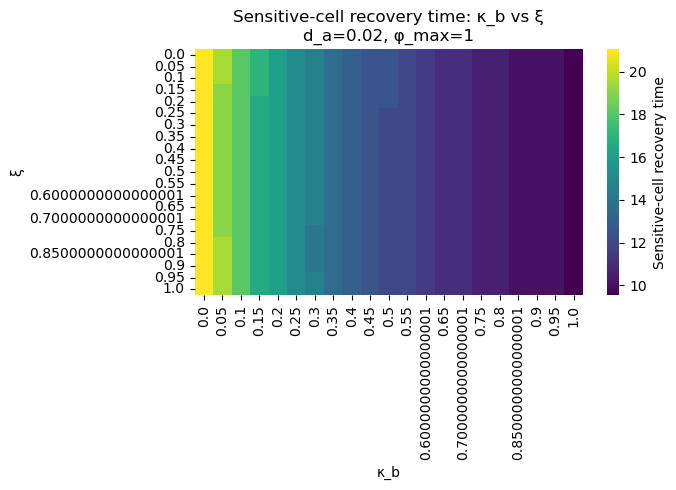

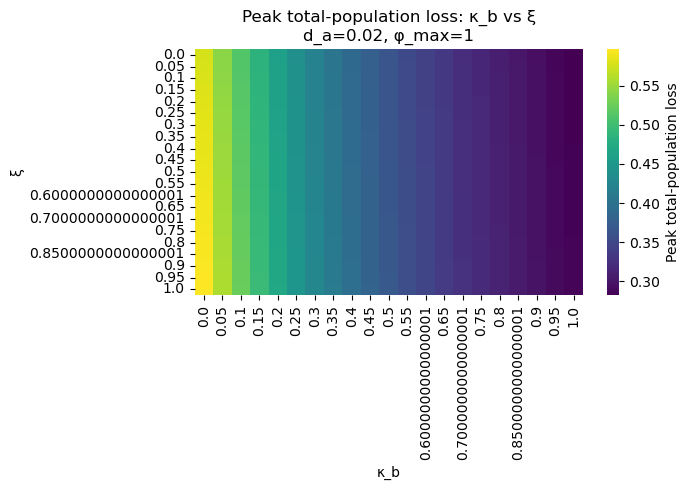

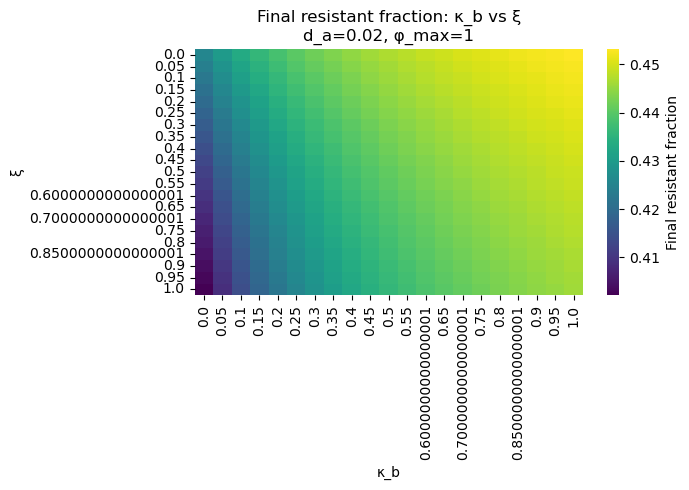

In [3]:
for outcome in ['diversity_final', 't_recovery_S', 'peak_loss_total', 'f_R_final']:
    heatmap(outcome, x='kappa_b', y='xi')
    plt.show()

## 3. Compare parameter pairs

These plots show whether the conclusions depend mainly on κ_b and ξ, or whether resistant-cell degradation and basal decay create different response regions.

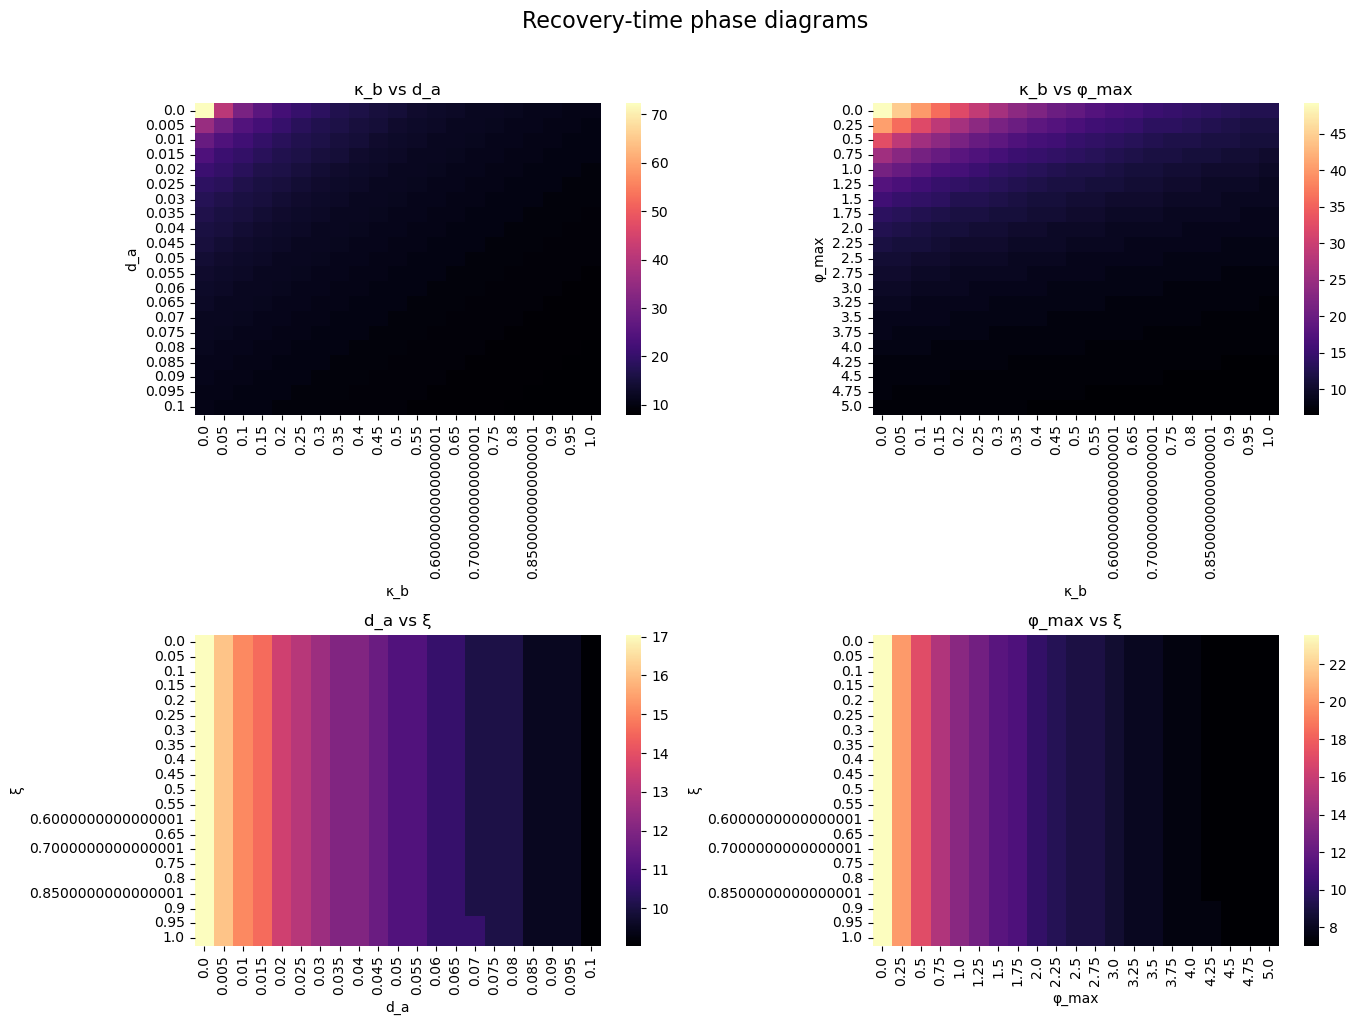

In [4]:
pairs = [('kappa_b', 'd_a'), ('kappa_b', 'phi_max'), ('d_a', 'xi'), ('phi_max', 'xi')]
outcome = 't_recovery_S'
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (x, y) in zip(axes.flat, pairs):
    subset = df.copy()
    for p in PARAMS:
        if p not in (x, y): subset = subset[np.isclose(subset[p], nearest_value(p))]
    table = subset.pivot(index=y, columns=x, values=outcome).sort_index()
    sns.heatmap(table, ax=ax, cmap='magma', cbar=True)
    ax.set_xlabel(LABELS[x]); ax.set_ylabel(LABELS[y]); ax.set_title(f'{LABELS[x]} vs {LABELS[y]}')
fig.suptitle('Recovery-time phase diagrams', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

## 4. Survival and collapse map

This categorical map makes the biological outcome easy to communicate: sensitive cells survive versus fail, and resistant cells are eliminated versus retained.

/var/folders/d7/rgjpwt31019czzdds44x_g3w0000gp/T/ipykernel_41843/1787947071.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  codes = pivot.replace({'S survives / R retained': 0, 'S survives / R eliminated': 1, 'S fails': 2, 'other': 3})


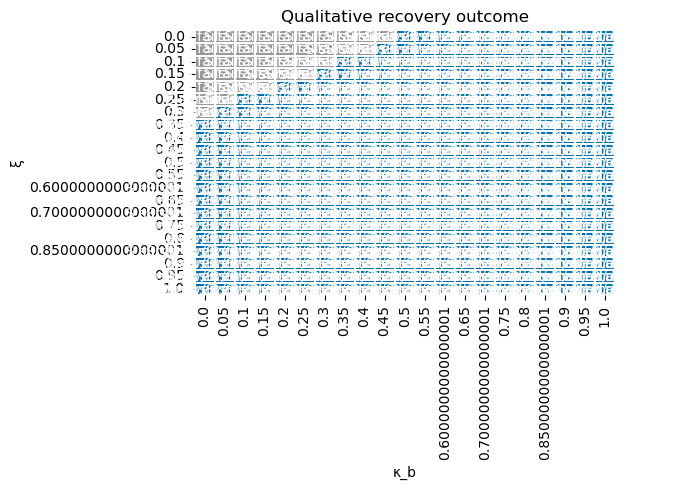

In [5]:
plot_df = df.copy()
plot_df['outcome_class'] = np.select([plot_df['sensitive_survives'] & ~plot_df['resistant_eliminated'], plot_df['sensitive_survives'] & plot_df['resistant_eliminated'], ~plot_df['sensitive_survives']], ['S survives / R retained', 'S survives / R eliminated', 'S fails'], default='other')
subset = plot_df.copy()
for p in PARAMS:
    if p not in ('kappa_b', 'xi'): subset = subset[np.isclose(subset[p], nearest_value(p))]
pivot = subset.pivot(index='xi', columns='kappa_b', values='outcome_class')
codes = pivot.replace({'S survives / R retained': 0, 'S survives / R eliminated': 1, 'S fails': 2, 'other': 3})
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(codes, ax=ax, cmap=sns.color_palette(['#0072B2','#009E73','#D55E00','#999999']), cbar=False, annot=pivot, fmt='', linewidths=.2)
ax.set_xlabel('κ_b'); ax.set_ylabel('ξ'); ax.set_title('Qualitative recovery outcome')
plt.tight_layout(); plt.show()

## 5. Time-course sensitivity analysis

For each focal parameter, this plots n_s and n_r across a range of values while holding the other three Person 4 parameters at their baseline values. This shows *how* the trajectory changes, not only the final endpoint.

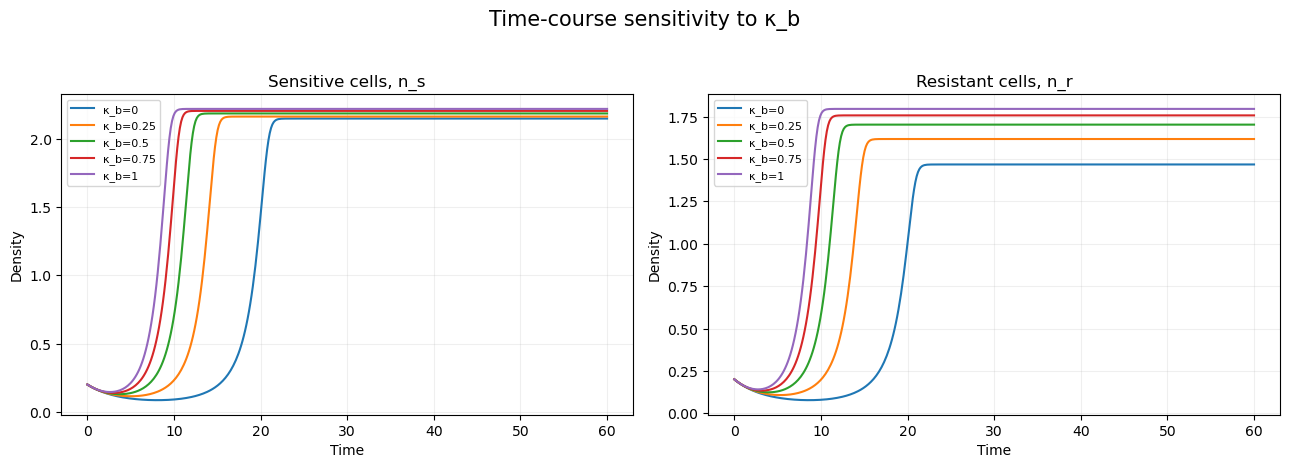

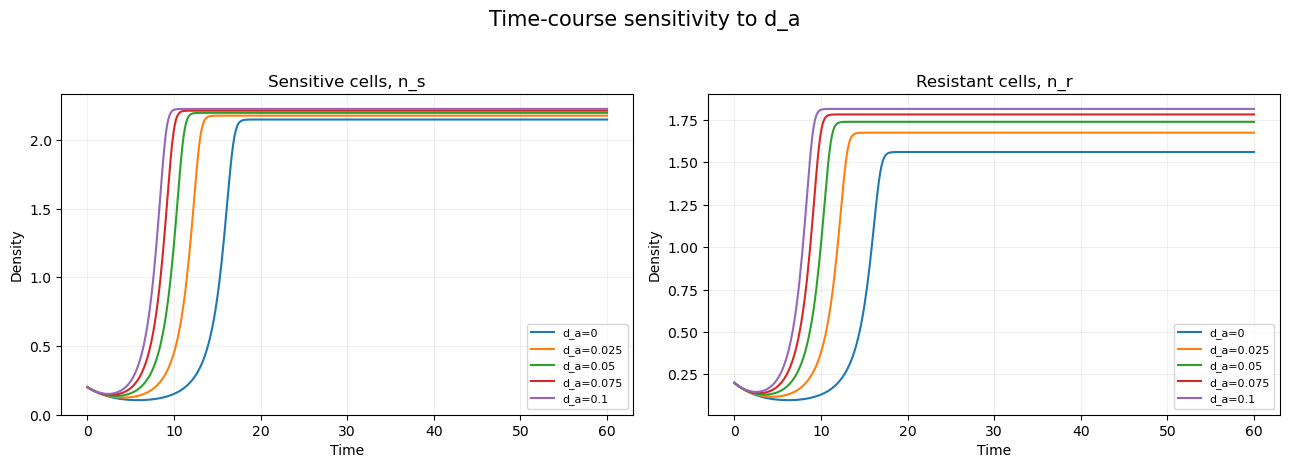

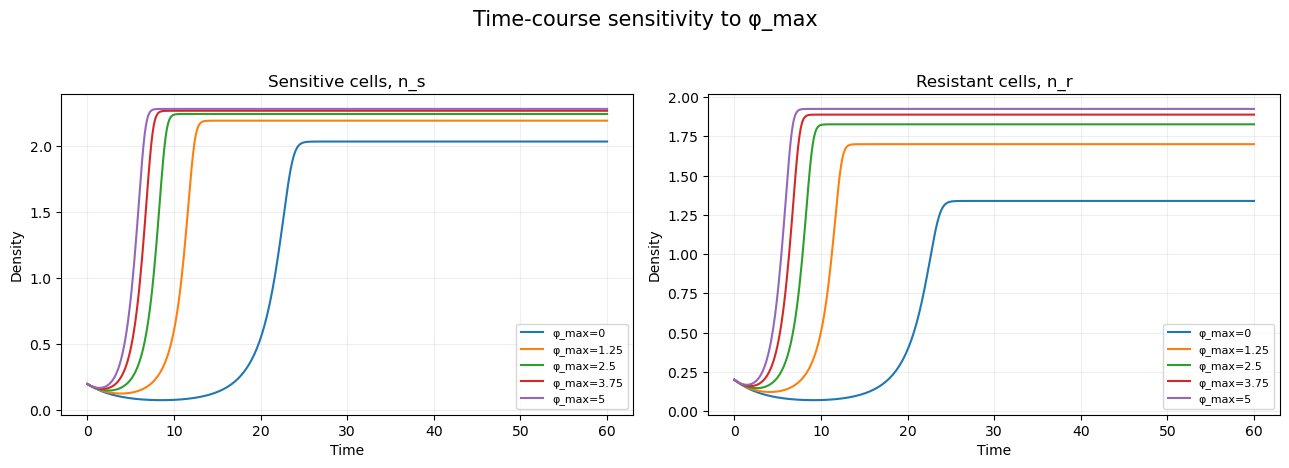

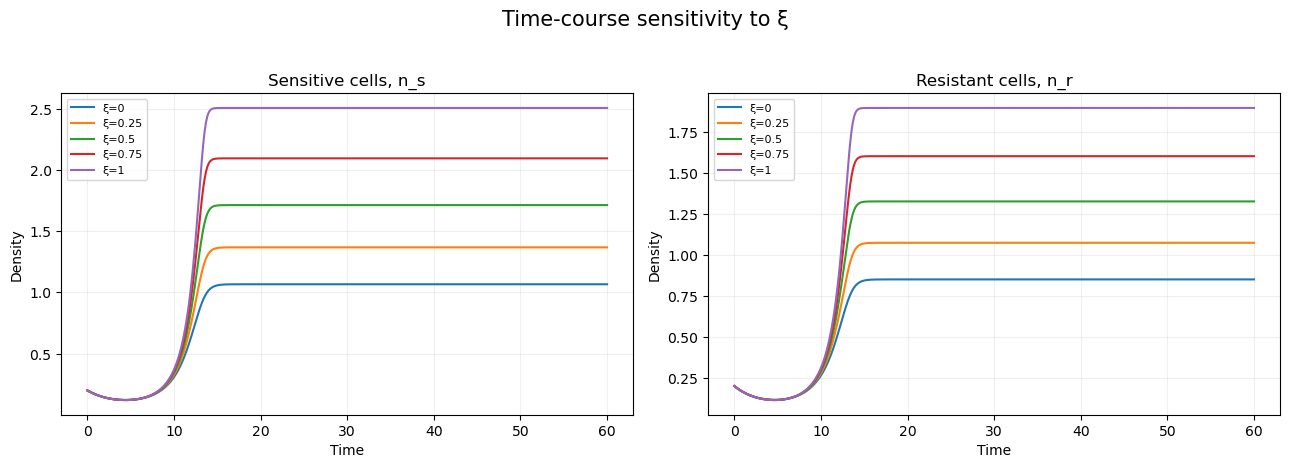

In [6]:
def parameter_values(parameter, n=5):
    values = np.sort(df[parameter].unique())
    return values[np.linspace(0, len(values)-1, n).round().astype(int)]

def plot_population_sensitivity(parameter, values=None, a0=2.15, i_dose=10.0, t_end=60):
    values = parameter_values(parameter) if values is None else values
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
    for value in values:
        p = replace(DEFAULT_PARAMS, **{parameter: float(value)})
        sol = simulate_logspace(p, a0=a0, i_dose=i_dose, t_span=(0, t_end), n_points=400)
        axes[0].plot(sol.t, sol.ns, label=f'{LABELS[parameter]}={value:g}')
        axes[1].plot(sol.t, sol.nr, label=f'{LABELS[parameter]}={value:g}')
    axes[0].set_title('Sensitive cells, n_s'); axes[1].set_title('Resistant cells, n_r')
    for ax in axes: ax.set_xlabel('Time'); ax.set_ylabel('Density'); ax.legend(fontsize=8); ax.grid(alpha=.2)
    fig.suptitle(f'Time-course sensitivity to {LABELS[parameter]}', y=1.03, fontsize=15)
    plt.tight_layout(); return fig, axes

for parameter in PARAMS:
    plot_population_sensitivity(parameter)
    plt.show()

## 6. Optional: antibiotic and nutrient trajectories

These traces help explain *why* the population trajectories differ. The five ODE states are n_s, n_r, nutrient s, antibiotic a, and free β-lactamase b.

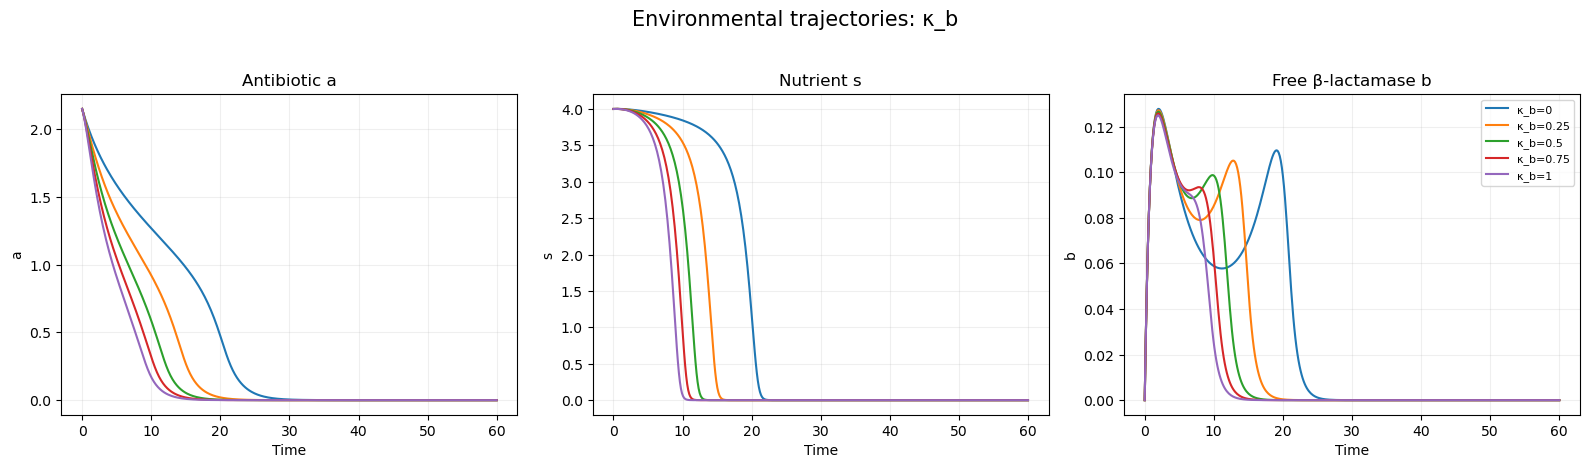

In [7]:
def plot_environment_sensitivity(parameter, values=None, a0=2.15, i_dose=10.0, t_end=60):
    values = parameter_values(parameter) if values is None else values
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
    for value in values:
        p = replace(DEFAULT_PARAMS, **{parameter: float(value)})
        sol = simulate_logspace(p, a0=a0, i_dose=i_dose, t_span=(0, t_end), n_points=400)
        label = f'{LABELS[parameter]}={value:g}'
        axes[0].plot(sol.t, sol.a, label=label)
        axes[1].plot(sol.t, sol.s, label=label)
        axes[2].plot(sol.t, sol.b, label=label)
    for ax, title, ylabel in zip(axes, ['Antibiotic a', 'Nutrient s', 'Free β-lactamase b'], ['a', 's', 'b']):
        ax.set_title(title); ax.set_xlabel('Time'); ax.set_ylabel(ylabel); ax.grid(alpha=.2)
    axes[-1].legend(fontsize=8)
    fig.suptitle(f'Environmental trajectories: {LABELS[parameter]}', y=1.03, fontsize=15)
    plt.tight_layout(); return fig, axes

plot_environment_sensitivity('kappa_b'); plt.show()

## Interpretation guide

Look for broad color regions, sharp boundaries, and curved boundaries. Broad regions indicate robust behavior; sharp or curved boundaries indicate threshold-like effects or parameter interactions. Compare the heatmaps with the time-course plots to connect endpoint summaries to the underlying crash-and-recovery trajectories.

# Additional Analyses

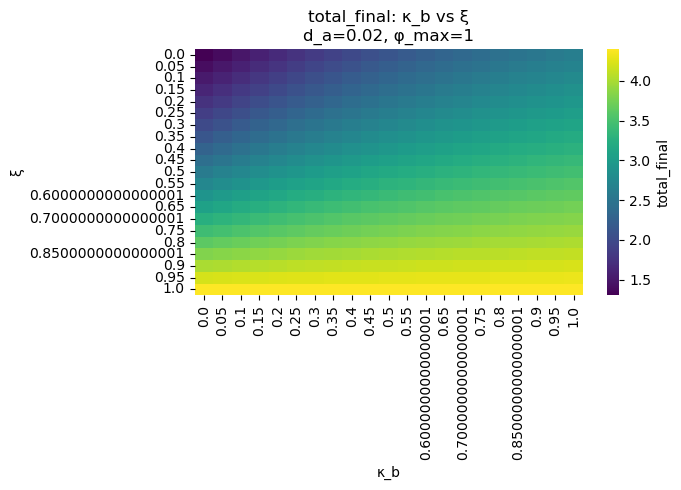

In [8]:
df["total_final"] = df["ns_final"] + df["nr_final"]

heatmap(
    outcome="total_final",
    x="kappa_b",
    y="xi",
    cmap="viridis"
)
plt.show()

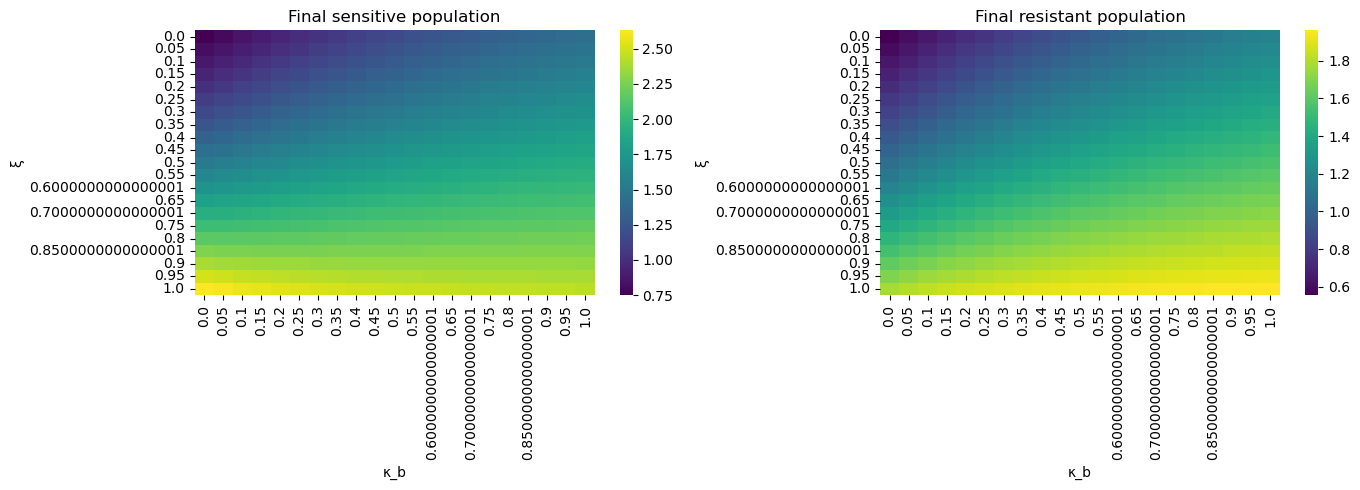

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, outcome, title in zip(
    axes,
    ["ns_final", "nr_final"],
    ["Final sensitive population", "Final resistant population"]
):
    subset = df.copy()

    for p in PARAMS:
        if p not in ["kappa_b", "xi"]:
            subset = subset[
                np.isclose(subset[p], nearest_value(p))
            ]

    table = subset.pivot(
        index="xi",
        columns="kappa_b",
        values=outcome
    ).sort_index()

    sns.heatmap(table, ax=ax, cmap="viridis")
    ax.set_xlabel("κ_b")
    ax.set_ylabel("ξ")
    ax.set_title(title)

plt.tight_layout()
plt.show()

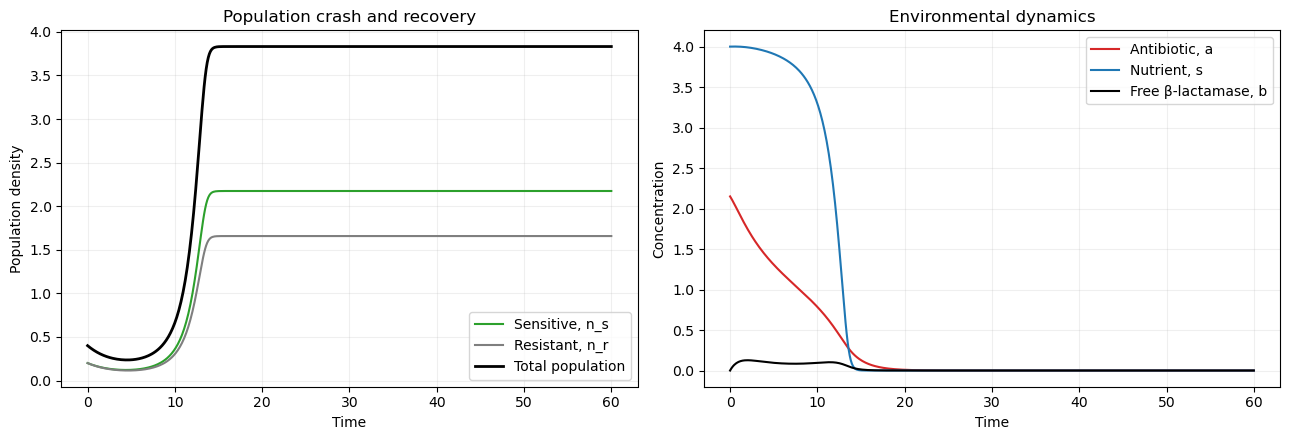

In [10]:
from dataclasses import replace
from ma2024_model import DEFAULT_PARAMS
from sweep_engine import simulate_logspace

def plot_population_trajectory(kappa_b, d_a, phi_max, xi, t_end=60):
    p = replace(
        DEFAULT_PARAMS,
        kappa_b=kappa_b,
        d_a=d_a,
        phi_max=phi_max,
        xi=xi
    )

    sol = simulate_logspace(
        p,
        a0=2.15,
        i_dose=10,
        t_span=(0, t_end),
        n_points=500
    )

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].plot(sol.t, sol.ns, label="Sensitive, n_s", color="tab:green")
    axes[0].plot(sol.t, sol.nr, label="Resistant, n_r", color="tab:gray")
    axes[0].plot(
        sol.t,
        sol.ns + sol.nr,
        label="Total population",
        color="black",
        linewidth=2
    )
    axes[0].set_xlabel("Time")
    axes[0].set_ylabel("Population density")
    axes[0].set_title("Population crash and recovery")
    axes[0].legend()
    axes[0].grid(alpha=0.2)

    axes[1].plot(sol.t, sol.a, label="Antibiotic, a", color="tab:red")
    axes[1].plot(sol.t, sol.s, label="Nutrient, s", color="tab:blue")
    axes[1].plot(sol.t, sol.b, label="Free β-lactamase, b", color="black")
    axes[1].set_xlabel("Time")
    axes[1].set_ylabel("Concentration")
    axes[1].set_title("Environmental dynamics")
    axes[1].legend()
    axes[1].grid(alpha=0.2)

    plt.tight_layout()
    return fig, axes

plot_population_trajectory(
    kappa_b=0.35,
    d_a=0.02,
    phi_max=1.0,
    xi=0.8
)
plt.show()